<a href="https://colab.research.google.com/github/falcon23nk/collab-project/blob/main/practica_2_3_teachable_machinee.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Teachable Machine**

En esta práctica se debe exportar el modelo que se genera en Teachable Machine.

A la hora de exportar el modelo, se puede exportar para Tensorflow.

También viene un fragmento de código para usar el modelo:

```
from keras.models import load_model  # TensorFlow is required for Keras to work
from PIL import Image, ImageOps  # Install pillow instead of PIL
import numpy as np

# Disable scientific notation for clarity
np.set_printoptions(suppress=True)

# Load the model
model = load_model("keras_Model.h5", compile=False)

# Load the labels
class_names = open("labels.txt", "r").readlines()

# Create the array of the right shape to feed into the keras model
# The 'length' or number of images you can put into the array is
# determined by the first position in the shape tuple, in this case 1
data = np.ndarray(shape=(1, 224, 224, 3), dtype=np.float32)

# Replace this with the path to your image
image = Image.open("<IMAGE_PATH>").convert("RGB")

# resizing the image to be at least 224x224 and then cropping from the center
size = (224, 224)
image = ImageOps.fit(image, size, Image.Resampling.LANCZOS)

# turn the image into a numpy array
image_array = np.asarray(image)

# Normalize the image
normalized_image_array = (image_array.astype(np.float32) / 127.5) - 1

# Load the image into the array
data[0] = normalized_image_array

# Predicts the model
prediction = model.predict(data)
index = np.argmax(prediction)
class_name = class_names[index]
confidence_score = prediction[0][index]

# Print prediction and confidence score
print("Class:", class_name[2:], end="")
print("Confidence Score:", confidence_score)

```

**Tarea**: subir 3 imágenes propias (una clara, una ambigua, una que no pertenezca a ninguna categoría) y anotar qué predice y con qué confianza.

**¡Ojo! Hay que cargar una  versión anterior de Keras**

In [5]:
# forzar TensorFlow a usar el comportamiento clásico de Keras 2
import os
os.environ['TF_USE_LEGACY_KERAS'] = '1'

import tensorflow as tf
import tf_keras as keras

print("Versión de TensorFlow:", tf.__version__)
print("Versión de TF-Keras (Legacy):", keras.__version__)

try:
    # Cargamos el modelo utilizando el módulo de compatibilidad oficial tf_keras
    model = keras.models.load_model('keras_model.h5', compile=False)
    print("\n¡MODELO CARGADO CON ÉXITO!")
    model.summary()
except Exception as e:
    print(f"\nError al cargar: {e}")

Versión de TensorFlow: 2.21.0
Versión de TF-Keras (Legacy): 2.21.0

¡MODELO CARGADO CON ÉXITO!
Model: "sequential_4"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 sequential_1 (Sequential)   (None, 1280)              410208    
                                                                 
 sequential_3 (Sequential)   (None, 2)                 128300    
                                                                 
Total params: 538508 (2.05 MB)
Trainable params: 524428 (2.00 MB)
Non-trainable params: 14080 (55.00 KB)
_________________________________________________________________


In [6]:
# Comprobacion rapida: que etiquetas tiene el modelo y que entrada espera
from PIL import Image, ImageOps
from IPython.display import display
import numpy as np

class_names = [l.strip() for l in open("labels.txt", encoding="utf-8") if l.strip()]
print("Clases del modelo:", class_names)
print("Entrada que espera:", model.input_shape)

Clases del modelo: ['0 Teclado', '1 Botella']
Entrada que espera: (None, 224, 224, 3)


In [7]:
# Funcion que clasifica una imagen y muestra el reparto completo de porcentajes.
# Se usa en los tres apartados siguientes.

UMBRAL = 0.90   # a partir de aqui damos el objeto por reconocido

def clasificar(ruta, titulo=""):
    # 1) dejar la imagen como la espera el modelo: 224x224, RGB y valores entre -1 y 1
    imagen = Image.open(ruta).convert("RGB")
    imagen = ImageOps.fit(imagen, (224, 224), Image.Resampling.LANCZOS)
    datos = np.asarray(imagen).astype(np.float32)
    datos = ((datos / 127.5) - 1).reshape(1, 224, 224, 3)

    # 2) pasarla por el modelo
    prediccion = model.predict(datos, verbose=0)[0]

    # 3) mostrar el resultado
    print(f"--- {titulo or ruta} ---")
    for nombre, p in zip(class_names, prediccion):
        etiqueta = nombre.split(" ", 1)[-1]      # "0 Botella" -> "Botella"
        print(f"  {etiqueta:<12} {p*100:6.2f} %  {'#' * int(p * 30)}")

    i = int(np.argmax(prediccion))
    ganadora = class_names[i].split(" ", 1)[-1]
    confianza = float(prediccion[i])

    if confianza >= UMBRAL:
        print(f"  => Reconocido como {ganadora} ({confianza*100:.2f} %)\n")
    else:
        print(f"  => Sin coincidencia clara: la mas alta es {ganadora} con "
              f"{confianza*100:.2f} %, por debajo del {UMBRAL*100:.0f} % exigido\n")

    display(imagen)
    return ganadora, confianza

---
## 1. Imagen que pertenece claramente a una categoría

--- Imagen de entrenamiento ---
  Teclado       99.99 %  #############################
  Botella        0.01 %  
  => Reconocido como Teclado (99.99 %)



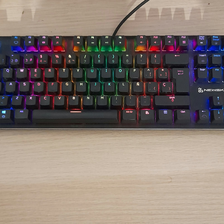

('Teclado', 0.9999498128890991)

In [8]:
# 1. Imagen que pertenece claramente a una categoria
#    Usa una de las fotos con las que entrenaste: deberia dar practicamente el 100 %.

clasificar("teclado1.jpeg", "Imagen de entrenamiento")

## 2. Imagen ambigua

--- Botella y teclado juntos ---
  Teclado       99.82 %  #############################
  Botella        0.18 %  
  => Reconocido como Teclado (99.82 %)



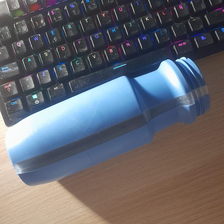

('Teclado', 0.9981928467750549)

In [9]:
# 2. Imagen ambigua: la botella y el teclado aparecen juntos en la misma foto,
#    asi que el modelo tiene que repartir entre las dos clases.

clasificar("doble.jpeg", "Botella y teclado juntos")

## 3. Imagen que no pertenece a ninguna categoría

--- Objeto que el modelo no conoce ---
  Teclado        3.11 %  
  Botella       96.89 %  #############################
  => Reconocido como Botella (96.89 %)



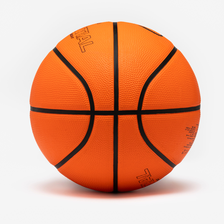

('Botella', 0.9689498543739319)

In [10]:
# 3. Imagen que no pertenece a ninguna categoria del modelo

clasificar("baloncesto.jpg", "Objeto que el modelo no conoce")

**¿Cómo se usa el modelo exportado? ¿Cómo se comporta?**

---



Para usar el modelo exportado por Teachable Machine necesitamos dos archivos (keras_model.h5 con la red y los pesos, y labels.txt con las clases). Como es un formato antiguo de Keras 2, hay que cargarlo con tf_keras. Antes de meter una foto a clasificar, hay que prepararla igual que en el entrenamiento: recortarla a 224 × 224 píxeles y cambiar los valores de color de 0–255 a un rango de −1 a 1. Al final, con predict nos da los porcentajes de cada clase.¿Cómo se comporta?Foto de entrenamiento: Da casi el 100 % (un 99.99 % en nuestro caso) porque el modelo ya la había visto antes. Es lo normal, pero no significa que funcione igual con fotos nuevas.   Foto con dos objetos: Como la botella y el teclado salen juntos, el modelo reparte los porcentajes pero le da casi todo al que ocupa más o se ve mejor (99.82 % al teclado). No te dice que hay dos cosas, solo elige una.   Foto de un objeto desconocido: Con el balón de baloncesto, que no lo conoce de nada, el modelo reparte el 100 % entre lo que sí conoce y le da un 96.89 % a la botella. El modelo nunca dice «no lo sé».   Aquí es donde se ve el gran fallo: el programa tenía puesto un umbral del 90 %, y como la pelota dio 96.89 %, no la descartó. O sea, el modelo estaba súper seguro de algo totalmente falso, que es la mayor limitación que tiene.